# 04 — Reinforcement Learning: Fine-Tuning via Self-Play Against Minimax

> **Google Colab:** Go to `Runtime → Change runtime type → GPU` for faster ResNet training.

This notebook:
1. Loads pre-trained **ResNet** and **XGBoost** models
2. Plays games against **Minimax** (alpha-beta, depth 4) — collecting (board_state, outcome) pairs
3. Fine-tunes both models on the game data
4. Repeats for multiple rounds (5 rounds of 200 games each)
5. Evaluates improvement: win rate vs Minimax after each round
6. Saves improved models to Google Drive

In [1]:
!pip install -q xgboost ucimlrepo

In [2]:
import numpy as np
import random
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
import xgboost as xgb
import matplotlib.pyplot as plt

# Board constants (must match app/engine.py)
ROWS = 6
COLS = 7
EMPTY = 0
PLAYER1 = 1
PLAYER2 = 2

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cuda


## 1. Game Engine (Self-Contained)

The Connect-4 game engine is defined inline so this notebook runs on
Google Colab without importing from `app/`. Identical to `app/engine.py`.

In [3]:
class ConnectFourGame:
    """Connect-4 game state and logic.

    Board layout: row 0 = top, row 5 = bottom.
    Values: 0 = empty, 1 = player 1, 2 = player 2.
    """

    def __init__(self):
        self.board = np.zeros((ROWS, COLS), dtype=np.int8)
        self.current_player = PLAYER1
        self.move_count = 0
        self._last_winner = None

    def get_valid_moves(self):
        return [c for c in range(COLS) if self.board[0][c] == EMPTY]

    def make_move(self, col):
        if col < 0 or col >= COLS or self.board[0][col] != EMPTY:
            return -1
        for row in range(ROWS - 1, -1, -1):
            if self.board[row][col] == EMPTY:
                self.board[row][col] = self.current_player
                self.move_count += 1
                self._last_winner = None
                self.current_player = PLAYER2 if self.current_player == PLAYER1 else PLAYER1
                return row
        return -1

    def undo_move(self, col):
        for row in range(ROWS):
            if self.board[row][col] != EMPTY:
                self.board[row][col] = EMPTY
                self.move_count -= 1
                self._last_winner = None
                self.current_player = PLAYER2 if self.current_player == PLAYER1 else PLAYER1
                return
        raise ValueError(f'Cannot undo move on empty column {col}')

    def check_winner(self):
        if self._last_winner is not None:
            return self._last_winner
        b = self.board
        for r in range(ROWS):
            for c in range(COLS - 3):
                val = b[r][c]
                if val != EMPTY and val == b[r][c+1] == b[r][c+2] == b[r][c+3]:
                    self._last_winner = val
                    return val
        for r in range(ROWS - 3):
            for c in range(COLS):
                val = b[r][c]
                if val != EMPTY and val == b[r+1][c] == b[r+2][c] == b[r+3][c]:
                    self._last_winner = val
                    return val
        for r in range(ROWS - 3):
            for c in range(COLS - 3):
                val = b[r][c]
                if val != EMPTY and val == b[r+1][c+1] == b[r+2][c+2] == b[r+3][c+3]:
                    self._last_winner = val
                    return val
        for r in range(3, ROWS):
            for c in range(COLS - 3):
                val = b[r][c]
                if val != EMPTY and val == b[r-1][c+1] == b[r-2][c+2] == b[r-3][c+3]:
                    self._last_winner = val
                    return val
        self._last_winner = 0
        return 0

    def is_full(self):
        return self.move_count >= ROWS * COLS

    def is_terminal(self):
        return self.check_winner() != 0 or self.is_full()

    def to_tensor(self):
        """3x6x7 one-hot tensor from current player's perspective."""
        opponent = PLAYER2 if self.current_player == PLAYER1 else PLAYER1
        tensor = np.zeros((3, ROWS, COLS), dtype=np.float32)
        tensor[0] = (self.board == self.current_player).astype(np.float32)
        tensor[1] = (self.board == opponent).astype(np.float32)
        tensor[2] = (self.board == EMPTY).astype(np.float32)
        return tensor

    def clone(self):
        new_game = ConnectFourGame()
        new_game.board = self.board.copy()
        new_game.current_player = self.current_player
        new_game.move_count = self.move_count
        new_game._last_winner = self._last_winner
        return new_game

print('Game engine loaded.')

Game engine loaded.


## 2. Minimax Agent (Opponent)

Alpha-beta pruning with heuristic evaluation. This is the opponent our
models will train against. Identical to `app/agents/minimax_agent.py`.

In [4]:
# Center-first move ordering for better alpha-beta pruning
MOVE_ORDER = [3, 2, 4, 1, 5, 0, 6]

# Precompute all 69 possible 4-cell windows on a 6x7 board
WINDOWS = []
for r in range(ROWS):
    for c in range(COLS - 3):
        WINDOWS.append([(r, c), (r, c+1), (r, c+2), (r, c+3)])
for r in range(ROWS - 3):
    for c in range(COLS):
        WINDOWS.append([(r, c), (r+1, c), (r+2, c), (r+3, c)])
for r in range(ROWS - 3):
    for c in range(COLS - 3):
        WINDOWS.append([(r, c), (r+1, c+1), (r+2, c+2), (r+3, c+3)])
for r in range(3, ROWS):
    for c in range(COLS - 3):
        WINDOWS.append([(r, c), (r-1, c+1), (r-2, c+2), (r-3, c+3)])


class MinimaxAgent:
    """Alpha-Beta Minimax agent with configurable search depth."""

    def __init__(self, player_id=PLAYER1, depth=6):
        self.player_id = player_id
        self.depth = depth

    @property
    def name(self):
        return 'Minimax'

    def select_move(self, game):
        start = time.perf_counter()
        score, move = self._alpha_beta(
            game, self.depth, float('-inf'), float('inf'), True
        )
        elapsed_ms = (time.perf_counter() - start) * 1000
        if move is None:
            valid = game.get_valid_moves()
            move = valid[0] if valid else 0
        return {'move': move, 'score': score, 'depth': self.depth,
                'compute_time_ms': elapsed_ms}

    def _alpha_beta(self, game, depth, alpha, beta, maximizing):
        winner = game.check_winner()
        if winner == self.player_id:
            return 100_000 + depth, None
        if winner != 0:
            return -100_000 - depth, None
        if game.is_full():
            return 0, None
        if depth == 0:
            return self._evaluate(game), None

        valid_moves = [c for c in MOVE_ORDER if c in game.get_valid_moves()]

        if maximizing:
            max_eval = float('-inf')
            best_move = valid_moves[0]
            for col in valid_moves:
                game.make_move(col)
                eval_score, _ = self._alpha_beta(game, depth - 1, alpha, beta, False)
                game.undo_move(col)
                if eval_score > max_eval:
                    max_eval = eval_score
                    best_move = col
                alpha = max(alpha, eval_score)
                if beta <= alpha:
                    break
            return max_eval, best_move
        else:
            min_eval = float('inf')
            best_move = valid_moves[0]
            for col in valid_moves:
                game.make_move(col)
                eval_score, _ = self._alpha_beta(game, depth - 1, alpha, beta, True)
                game.undo_move(col)
                if eval_score < min_eval:
                    min_eval = eval_score
                    best_move = col
                beta = min(beta, eval_score)
                if beta <= alpha:
                    break
            return min_eval, best_move

    def _evaluate(self, game):
        board = game.board
        opponent = PLAYER2 if self.player_id == PLAYER1 else PLAYER1
        score = 0
        center_col = board[:, 3]
        score += int((center_col == self.player_id).sum()) * 6
        for window in WINDOWS:
            cells = [board[r][c] for r, c in window]
            own = cells.count(self.player_id)
            opp = cells.count(opponent)
            empty = cells.count(EMPTY)
            if own == 4:
                score += 100_000
            elif own == 3 and empty == 1:
                score += 50
            elif own == 2 and empty == 2:
                score += 10
            if opp == 4:
                score -= 100_000
            elif opp == 3 and empty == 1:
                score -= 50
            elif opp == 2 and empty == 2:
                score -= 10
        return score

print(f'Minimax agent loaded. {len(WINDOWS)} evaluation windows precomputed.')

Minimax agent loaded. 69 evaluation windows precomputed.


## 3. Model Architectures

ResNet architecture must match the pre-trained weights exactly
(5 blocks, 128 filters, dual policy+value heads).

In [5]:
class ResidualBlock(nn.Module):
    def __init__(self, num_filters):
        super().__init__()
        self.conv1 = nn.Conv2d(num_filters, num_filters, 3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(num_filters)
        self.conv2 = nn.Conv2d(num_filters, num_filters, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(num_filters)

    def forward(self, x):
        residual = x
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = out + residual
        return F.relu(out)


class Connect4ResNet(nn.Module):
    def __init__(self, num_blocks=5, num_filters=128):
        super().__init__()
        self.initial_conv = nn.Conv2d(3, num_filters, 3, padding=1, bias=False)
        self.initial_bn = nn.BatchNorm2d(num_filters)
        self.blocks = nn.Sequential(
            *[ResidualBlock(num_filters) for _ in range(num_blocks)]
        )
        self.policy_conv = nn.Conv2d(num_filters, 2, 1, bias=False)
        self.policy_bn = nn.BatchNorm2d(2)
        self.policy_fc = nn.Linear(2 * ROWS * COLS, COLS)
        self.value_conv = nn.Conv2d(num_filters, 1, 1, bias=False)
        self.value_bn = nn.BatchNorm2d(1)
        self.value_fc1 = nn.Linear(ROWS * COLS, 64)
        self.value_fc2 = nn.Linear(64, 1)

    def forward(self, x):
        out = F.relu(self.initial_bn(self.initial_conv(x)))
        out = self.blocks(out)
        p = F.relu(self.policy_bn(self.policy_conv(out)))
        p = p.view(p.size(0), -1)
        p = self.policy_fc(p)
        v = F.relu(self.value_bn(self.value_conv(out)))
        v = v.view(v.size(0), -1)
        v = F.relu(self.value_fc1(v))
        v = torch.tanh(self.value_fc2(v))
        return p, v

print('ResNet architecture loaded.')

ResNet architecture loaded.


## 4. Load Pre-Trained Models

Upload your pre-trained weights from Google Drive. These models were
trained on the UCI Connect-4 dataset (67,557 positions) in notebooks 01 and 03.

In [6]:
from google.colab import drive
drive.mount('/content/drive')

# --- ResNet ---
resnet_path = '/content/drive/MyDrive/connect4_resnet.pt'
resnet_model = Connect4ResNet(num_blocks=5, num_filters=128).to(device)
resnet_model.load_state_dict(torch.load(resnet_path, map_location=device, weights_only=True))
resnet_model.eval()
print(f'ResNet loaded from {resnet_path}')

# --- XGBoost ---
xgboost_path = '/content/drive/MyDrive/connect4_xgboost.json'
xgboost_model = xgb.XGBRegressor()
xgboost_model.load_model(xgboost_path)
print(f'XGBoost loaded from {xgboost_path}')

Mounted at /content/drive
ResNet loaded from /content/drive/MyDrive/connect4_resnet.pt
XGBoost loaded from /content/drive/MyDrive/connect4_xgboost.json


## 5. Self-Play Infrastructure

Core functions for playing games and collecting training data:
- **Model-based move selection** with epsilon-greedy exploration
- **Game play loop** that records every board state
- **Data collection** that assigns game outcomes to each recorded position

In [7]:
def resnet_select_move(game, model, epsilon=0.1):
    """Select a move using ResNet with epsilon-greedy exploration.

    1-ply lookahead: for each valid col, clone game, play move,
    evaluate with value head, negate (perspective flip), pick best.
    """
    valid_moves = game.get_valid_moves()
    if random.random() < epsilon:
        return random.choice(valid_moves)

    values = {}
    with torch.no_grad():
        for col in valid_moves:
            game_copy = game.clone()
            game_copy.make_move(col)
            tensor = torch.tensor(game_copy.to_tensor(), device=device).unsqueeze(0)
            _, value = model(tensor)
            values[col] = -value.item()  # Negate: perspective flipped

    return max(values, key=values.get)


def xgboost_select_move(game, model, epsilon=0.1):
    """Select a move using XGBoost with epsilon-greedy exploration."""
    valid_moves = game.get_valid_moves()
    if random.random() < epsilon:
        return random.choice(valid_moves)

    values = {}
    for col in valid_moves:
        game_copy = game.clone()
        game_copy.make_move(col)
        flat = game_copy.to_tensor().reshape(1, -1)  # (1, 126)
        pred = model.predict(flat)[0]
        values[col] = -float(np.clip(pred, -1.0, 1.0))  # Negate

    return max(values, key=values.get)

print('Move selection functions loaded.')

Move selection functions loaded.


In [8]:
def play_game(model_select_fn, model, minimax, model_plays_as, epsilon=0.1):
    """Play one game between a model agent and Minimax.

    Records every board state (from current player's perspective) and
    assigns the game outcome to each position after the game ends.

    Returns:
        states: list of (3, 6, 7) numpy tensors
        values: list of float -- outcome from that state's player perspective
        winner: PLAYER1, PLAYER2, or 0 (draw)
    """
    game = ConnectFourGame()
    history = []  # (tensor, which_player_was_current)

    while not game.is_terminal():
        state_tensor = game.to_tensor().copy()
        current = game.current_player
        history.append((state_tensor, current))

        if current == model_plays_as:
            col = model_select_fn(game, model, epsilon=epsilon)
        else:
            result = minimax.select_move(game)
            col = result['move']

        game.make_move(col)

    winner = game.check_winner()

    # Assign values from each state's player's perspective
    states = []
    values = []
    for state_tensor, player_at_turn in history:
        if winner == 0:
            val = 0.0
        elif winner == player_at_turn:
            val = 1.0
        else:
            val = -1.0
        states.append(state_tensor)
        values.append(val)

    return states, values, winner


def play_games(model_select_fn, model, minimax_depth=4, num_games=200,
               epsilon=0.1, verbose=True):
    """Play multiple games, alternating which side the model plays."""
    minimax = MinimaxAgent(player_id=PLAYER1, depth=minimax_depth)

    all_states = []
    all_values = []
    stats = {'model_wins': 0, 'minimax_wins': 0, 'draws': 0}

    for i in range(num_games):
        # Alternate sides to avoid first-move bias
        if i % 2 == 0:
            model_plays_as = PLAYER1
            minimax.player_id = PLAYER2
        else:
            model_plays_as = PLAYER2
            minimax.player_id = PLAYER1

        states, values, winner = play_game(
            model_select_fn, model, minimax, model_plays_as, epsilon
        )
        all_states.extend(states)
        all_values.extend(values)

        if winner == 0:
            stats['draws'] += 1
        elif winner == model_plays_as:
            stats['model_wins'] += 1
        else:
            stats['minimax_wins'] += 1

        if verbose and (i + 1) % 50 == 0:
            total = i + 1
            print(f'  Game {total}/{num_games}: '
                  f'Model {stats["model_wins"]}W / '
                  f'{stats["minimax_wins"]}L / '
                  f'{stats["draws"]}D  |  '
                  f'{len(all_states)} positions collected')

    return all_states, all_values, stats

print('Self-play functions loaded.')

Self-play functions loaded.


## 6. Fine-Tuning Functions

- **ResNet**: Lower learning rate (1e-4), MSE loss on value head, batch training
- **XGBoost**: Retrain from scratch on UCI + self-play data combined

In [9]:
def finetune_resnet(model, states, values, epochs=10, lr=1e-4, batch_size=256):
    """Fine-tune ResNet on self-play data using MSE loss on value head.

    Uses a lower learning rate than original training (1e-3) to avoid
    catastrophic forgetting of the UCI pre-training.
    """
    model.train()

    X = torch.tensor(np.array(states), dtype=torch.float32)
    y = torch.tensor(np.array(values), dtype=torch.float32).unsqueeze(1)

    dataset = TensorDataset(X, y)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-4)
    criterion = nn.MSELoss()

    losses = []
    for epoch in range(epochs):
        epoch_loss = 0.0
        n_batches = 0
        for X_batch, y_batch in loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()
            _, value_pred = model(X_batch)
            loss = criterion(value_pred, y_batch)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item()
            n_batches += 1
        losses.append(epoch_loss / n_batches)

    model.eval()
    return losses

print('ResNet fine-tuning function loaded.')

ResNet fine-tuning function loaded.


In [10]:
# Fetch UCI data once (needed for XGBoost retraining each round)
from ucimlrepo import fetch_ucirepo

dataset = fetch_ucirepo(id=26)
X_uci = dataset.data.features
y_uci = dataset.data.targets

def parse_uci_to_tensors(X_df):
    n_samples = len(X_df)
    tensors = np.zeros((n_samples, 3, ROWS, COLS), dtype=np.float32)
    col_map = {'a': 0, 'b': 1, 'c': 2, 'd': 3, 'e': 4, 'f': 5, 'g': 6}
    for col_name in X_df.columns:
        board_col = col_map[col_name[0]]
        uci_row = int(col_name[1])
        board_row = ROWS - uci_row
        values = X_df[col_name].values
        tensors[:, 0, board_row, board_col] = (values == 'x').astype(np.float32)
        tensors[:, 1, board_row, board_col] = (values == 'o').astype(np.float32)
        tensors[:, 2, board_row, board_col] = (values == 'b').astype(np.float32)
    return tensors

def encode_labels(y_df):
    label_map = {'win': 1.0, 'loss': -1.0, 'draw': 0.0}
    return np.array([label_map[v] for v in y_df.iloc[:, 0].values], dtype=np.float32)

uci_tensors = parse_uci_to_tensors(X_uci)
uci_values = encode_labels(y_uci)
uci_flat = uci_tensors.reshape(len(uci_tensors), -1)  # (67557, 126)

print(f'UCI data loaded: {uci_flat.shape[0]} positions')

UCI data loaded: 67557 positions


In [11]:
def finetune_xgboost(states, values):
    """Retrain XGBoost from scratch on UCI + self-play data combined.

    XGBoost cannot be incrementally updated, so we retrain on the full
    combined dataset each round. This is fast (~10s on 70K+ samples).
    """
    sp_flat = np.array(states).reshape(len(states), -1)
    sp_values = np.array(values, dtype=np.float32)

    X_combined = np.concatenate([uci_flat, sp_flat], axis=0)
    y_combined = np.concatenate([uci_values, sp_values], axis=0)

    print(f'  XGBoost training on {len(X_combined)} samples '
          f'({len(uci_flat)} UCI + {len(sp_flat)} self-play)')

    model = xgb.XGBRegressor(
        n_estimators=500,
        max_depth=8,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_alpha=0.1,
        reg_lambda=1.0,
        random_state=42,
        verbosity=0,
    )
    model.fit(X_combined, y_combined)
    return model

print('XGBoost fine-tuning function loaded.')

XGBoost fine-tuning function loaded.


## 7. Evaluation Function

In [12]:
def evaluate_model(model_select_fn, model, minimax_depth=4, num_games=100):
    """Evaluate model win rate against Minimax with NO exploration (epsilon=0)."""
    minimax = MinimaxAgent(player_id=PLAYER1, depth=minimax_depth)
    results = []

    for i in range(num_games):
        if i % 2 == 0:
            model_plays_as = PLAYER1
            minimax.player_id = PLAYER2
        else:
            model_plays_as = PLAYER2
            minimax.player_id = PLAYER1

        game = ConnectFourGame()
        while not game.is_terminal():
            if game.current_player == model_plays_as:
                col = model_select_fn(game, model, epsilon=0.0)
            else:
                result = minimax.select_move(game)
                col = result['move']
            game.make_move(col)

        winner = game.check_winner()
        if winner == 0:
            results.append('draw')
        elif winner == model_plays_as:
            results.append('win')
        else:
            results.append('loss')

    wins = results.count('win')
    losses = results.count('loss')
    draws = results.count('draw')
    total = len(results)

    return {
        'win_rate': wins / total,
        'loss_rate': losses / total,
        'draw_rate': draws / total,
        'wins': wins, 'losses': losses, 'draws': draws, 'total': total,
    }

print('Evaluation function loaded.')

Evaluation function loaded.


## 8. Reinforcement Learning Loop

The main training loop:
1. Evaluate baseline win rate (round 0)
2. For each round:
   - Play 200 games with exploration (epsilon decays 0.15 → 0.05)
   - Fine-tune ResNet on self-play data
   - Retrain XGBoost on UCI + all accumulated self-play data
   - Evaluate both models (100 games, no exploration)
3. Track and display progress

In [13]:
# === RL Configuration ===
NUM_ROUNDS = 5
GAMES_PER_ROUND = 200
EVAL_GAMES = 100
MINIMAX_DEPTH = 4
RESNET_FINETUNE_EPOCHS = 10
RESNET_LR = 1e-4
EPSILON_START = 0.15
EPSILON_END = 0.05
EPSILON_DECAY = (EPSILON_START - EPSILON_END) / max(NUM_ROUNDS - 1, 1)

print(f'Training plan: {NUM_ROUNDS} rounds x {GAMES_PER_ROUND} games')
print(f'Estimated positions per round: ~{GAMES_PER_ROUND * 20}')
print(f'Epsilon schedule: {EPSILON_START} -> {EPSILON_END}')
print(f'Minimax depth: {MINIMAX_DEPTH}')

Training plan: 5 rounds x 200 games
Estimated positions per round: ~4000
Epsilon schedule: 0.15 -> 0.05
Minimax depth: 4


In [14]:
print('=' * 60)
print('BASELINE EVALUATION (Round 0 — Before Fine-Tuning)')
print('=' * 60)

print('\nEvaluating ResNet...')
resnet_baseline = evaluate_model(resnet_select_move, resnet_model,
                                  MINIMAX_DEPTH, EVAL_GAMES)
print(f'  ResNet vs Minimax(d={MINIMAX_DEPTH}): '
      f'{resnet_baseline["wins"]}W / {resnet_baseline["losses"]}L / '
      f'{resnet_baseline["draws"]}D  '
      f'(win rate: {resnet_baseline["win_rate"]*100:.1f}%)')

print('\nEvaluating XGBoost...')
xgboost_baseline = evaluate_model(xgboost_select_move, xgboost_model,
                                   MINIMAX_DEPTH, EVAL_GAMES)
print(f'  XGBoost vs Minimax(d={MINIMAX_DEPTH}): '
      f'{xgboost_baseline["wins"]}W / {xgboost_baseline["losses"]}L / '
      f'{xgboost_baseline["draws"]}D  '
      f'(win rate: {xgboost_baseline["win_rate"]*100:.1f}%)')

# Store results for plotting
resnet_history = {
    'win_rates': [resnet_baseline['win_rate']],
    'loss_rates': [resnet_baseline['loss_rate']],
    'draw_rates': [resnet_baseline['draw_rate']],
    'train_losses': [],
}
xgboost_history = {
    'win_rates': [xgboost_baseline['win_rate']],
    'loss_rates': [xgboost_baseline['loss_rate']],
    'draw_rates': [xgboost_baseline['draw_rate']],
}

BASELINE EVALUATION (Round 0 — Before Fine-Tuning)

Evaluating ResNet...
  ResNet vs Minimax(d=4): 0W / 50L / 50D  (win rate: 0.0%)

Evaluating XGBoost...
  XGBoost vs Minimax(d=4): 50W / 50L / 0D  (win rate: 50.0%)


In [15]:
# Accumulate all self-play data across rounds for XGBoost
all_xgb_states = []
all_xgb_values = []

print('=' * 60)
print('REINFORCEMENT LEARNING TRAINING')
print('=' * 60)

for round_num in range(1, NUM_ROUNDS + 1):
    epsilon = EPSILON_START - (round_num - 1) * EPSILON_DECAY
    print(f'\n{"=" * 60}')
    print(f'ROUND {round_num}/{NUM_ROUNDS}  |  epsilon={epsilon:.3f}')
    print(f'{"=" * 60}')

    # --- Phase 1: ResNet Self-Play ---
    print(f'\n--- ResNet Self-Play ({GAMES_PER_ROUND} games) ---')
    t0 = time.time()
    resnet_states, resnet_values, resnet_stats = play_games(
        resnet_select_move, resnet_model, MINIMAX_DEPTH,
        GAMES_PER_ROUND, epsilon
    )
    t_resnet = time.time() - t0
    print(f'  Collected {len(resnet_states)} positions in {t_resnet:.1f}s')
    print(f'  Self-play: Model {resnet_stats["model_wins"]}W / '
          f'{resnet_stats["minimax_wins"]}L / {resnet_stats["draws"]}D')

    # --- Phase 2: XGBoost Self-Play ---
    print(f'\n--- XGBoost Self-Play ({GAMES_PER_ROUND} games) ---')
    t0 = time.time()
    xgb_states, xgb_values, xgb_stats = play_games(
        xgboost_select_move, xgboost_model, MINIMAX_DEPTH,
        GAMES_PER_ROUND, epsilon
    )
    t_xgb = time.time() - t0
    print(f'  Collected {len(xgb_states)} positions in {t_xgb:.1f}s')
    print(f'  Self-play: Model {xgb_stats["model_wins"]}W / '
          f'{xgb_stats["minimax_wins"]}L / {xgb_stats["draws"]}D')

    all_xgb_states.extend(xgb_states)
    all_xgb_values.extend(xgb_values)

    # --- Phase 3: Fine-Tune ResNet ---
    print(f'\n--- Fine-Tuning ResNet ({RESNET_FINETUNE_EPOCHS} epochs) ---')
    losses = finetune_resnet(
        resnet_model, resnet_states, resnet_values,
        epochs=RESNET_FINETUNE_EPOCHS, lr=RESNET_LR
    )
    resnet_history['train_losses'].append(losses)
    print(f'  Loss: {losses[0]:.4f} -> {losses[-1]:.4f}')

    # --- Phase 4: Retrain XGBoost ---
    print(f'\n--- Retraining XGBoost (UCI + all self-play) ---')
    t0 = time.time()
    xgboost_model = finetune_xgboost(all_xgb_states, all_xgb_values)
    t_retrain = time.time() - t0
    print(f'  Retrained in {t_retrain:.1f}s')

    # --- Phase 5: Evaluate ---
    print(f'\n--- Evaluating ({EVAL_GAMES} games, epsilon=0) ---')

    resnet_eval = evaluate_model(resnet_select_move, resnet_model,
                                  MINIMAX_DEPTH, EVAL_GAMES)
    resnet_history['win_rates'].append(resnet_eval['win_rate'])
    resnet_history['loss_rates'].append(resnet_eval['loss_rate'])
    resnet_history['draw_rates'].append(resnet_eval['draw_rate'])

    xgboost_eval = evaluate_model(xgboost_select_move, xgboost_model,
                                   MINIMAX_DEPTH, EVAL_GAMES)
    xgboost_history['win_rates'].append(xgboost_eval['win_rate'])
    xgboost_history['loss_rates'].append(xgboost_eval['loss_rate'])
    xgboost_history['draw_rates'].append(xgboost_eval['draw_rate'])

    print(f'\n  ResNet  win rate: {resnet_eval["win_rate"]*100:.1f}% '
          f'({resnet_eval["wins"]}W/{resnet_eval["losses"]}L/{resnet_eval["draws"]}D)')
    print(f'  XGBoost win rate: {xgboost_eval["win_rate"]*100:.1f}% '
          f'({xgboost_eval["wins"]}W/{xgboost_eval["losses"]}L/{xgboost_eval["draws"]}D)')

print(f'\n{"=" * 60}')
print('TRAINING COMPLETE')
print(f'{"=" * 60}')

REINFORCEMENT LEARNING TRAINING

ROUND 1/5  |  epsilon=0.150

--- ResNet Self-Play (200 games) ---
  Game 50/200: Model 2W / 42L / 6D  |  1283 positions collected
  Game 100/200: Model 7W / 85L / 8D  |  2557 positions collected
  Game 150/200: Model 11W / 125L / 14D  |  3948 positions collected
  Game 200/200: Model 17W / 166L / 17D  |  5372 positions collected
  Collected 5372 positions in 43.1s
  Self-play: Model 17W / 166L / 17D

--- XGBoost Self-Play (200 games) ---
  Game 50/200: Model 6W / 44L / 0D  |  981 positions collected
  Game 100/200: Model 10W / 89L / 1D  |  2022 positions collected
  Game 150/200: Model 18W / 131L / 1D  |  3025 positions collected
  Game 200/200: Model 25W / 174L / 1D  |  4037 positions collected
  Collected 4037 positions in 41.2s
  Self-play: Model 25W / 174L / 1D

--- Fine-Tuning ResNet (10 epochs) ---
  Loss: 1.1998 -> 0.3255

--- Retraining XGBoost (UCI + all self-play) ---
  XGBoost training on 71594 samples (67557 UCI + 4037 self-play)
  Retrained

## 9. Training Progress Visualization

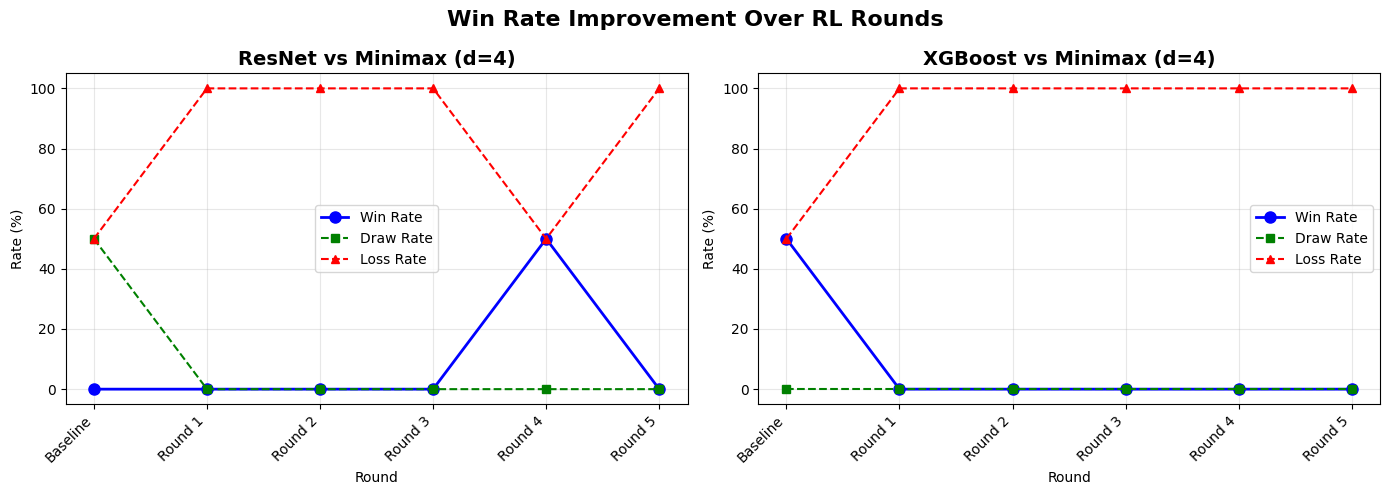

In [16]:
rounds = list(range(NUM_ROUNDS + 1))
round_labels = ['Baseline'] + [f'Round {i}' for i in range(1, NUM_ROUNDS + 1)]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ResNet
axes[0].plot(rounds, [r*100 for r in resnet_history['win_rates']],
             'b-o', linewidth=2, markersize=8, label='Win Rate')
axes[0].plot(rounds, [r*100 for r in resnet_history['draw_rates']],
             'g--s', linewidth=1.5, markersize=6, label='Draw Rate')
axes[0].plot(rounds, [r*100 for r in resnet_history['loss_rates']],
             'r--^', linewidth=1.5, markersize=6, label='Loss Rate')
axes[0].set_xlabel('Round')
axes[0].set_ylabel('Rate (%)')
axes[0].set_title(f'ResNet vs Minimax (d={MINIMAX_DEPTH})', fontsize=14, fontweight='bold')
axes[0].set_xticks(rounds)
axes[0].set_xticklabels(round_labels, rotation=45, ha='right')
axes[0].legend()
axes[0].grid(True, alpha=0.3)
axes[0].set_ylim(-5, 105)

# XGBoost
axes[1].plot(rounds, [r*100 for r in xgboost_history['win_rates']],
             'b-o', linewidth=2, markersize=8, label='Win Rate')
axes[1].plot(rounds, [r*100 for r in xgboost_history['draw_rates']],
             'g--s', linewidth=1.5, markersize=6, label='Draw Rate')
axes[1].plot(rounds, [r*100 for r in xgboost_history['loss_rates']],
             'r--^', linewidth=1.5, markersize=6, label='Loss Rate')
axes[1].set_xlabel('Round')
axes[1].set_ylabel('Rate (%)')
axes[1].set_title(f'XGBoost vs Minimax (d={MINIMAX_DEPTH})', fontsize=14, fontweight='bold')
axes[1].set_xticks(rounds)
axes[1].set_xticklabels(round_labels, rotation=45, ha='right')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
axes[1].set_ylim(-5, 105)

plt.suptitle('Win Rate Improvement Over RL Rounds', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

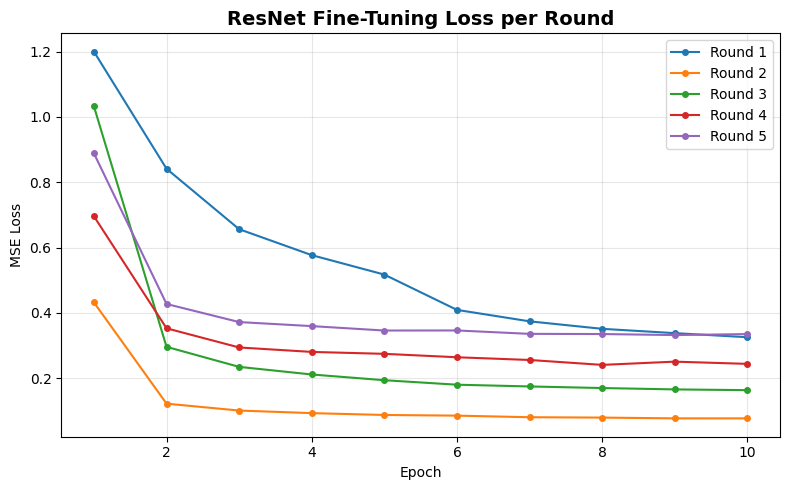

In [17]:
# ResNet training loss per round
fig, ax = plt.subplots(figsize=(8, 5))

for round_idx, losses in enumerate(resnet_history['train_losses'], 1):
    ax.plot(range(1, len(losses) + 1), losses, '-o', markersize=4,
            label=f'Round {round_idx}', linewidth=1.5)

ax.set_xlabel('Epoch')
ax.set_ylabel('MSE Loss')
ax.set_title('ResNet Fine-Tuning Loss per Round', fontsize=14, fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

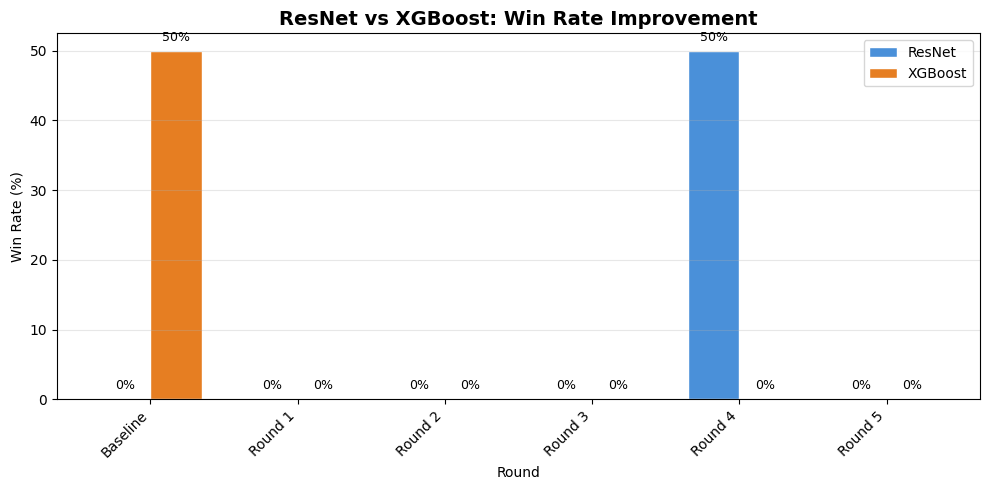

In [18]:
# Combined comparison bar chart
fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(NUM_ROUNDS + 1)
width = 0.35

resnet_wr = [r * 100 for r in resnet_history['win_rates']]
xgboost_wr = [r * 100 for r in xgboost_history['win_rates']]

bars1 = ax.bar(x - width/2, resnet_wr, width, label='ResNet',
               color='#4A90D9', edgecolor='white')
bars2 = ax.bar(x + width/2, xgboost_wr, width, label='XGBoost',
               color='#E67E22', edgecolor='white')

ax.set_xlabel('Round')
ax.set_ylabel('Win Rate (%)')
ax.set_title('ResNet vs XGBoost: Win Rate Improvement',
             fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(round_labels, rotation=45, ha='right')
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 1,
            f'{bar.get_height():.0f}%', ha='center', va='bottom', fontsize=9)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 1,
            f'{bar.get_height():.0f}%', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

## 10. Summary Statistics

In [19]:
print('=' * 70)
print('REINFORCEMENT LEARNING RESULTS SUMMARY')
print('=' * 70)
print(f'\nMinimax opponent depth: {MINIMAX_DEPTH}')
print(f'Games per round: {GAMES_PER_ROUND} (self-play) + {EVAL_GAMES} (eval)')
print(f'ResNet fine-tuning: {RESNET_FINETUNE_EPOCHS} epochs/round, lr={RESNET_LR}')
print(f'XGBoost: retrained on UCI + accumulated self-play each round\n')

print(f'{"Round":<12} {"ResNet Win%":<14} {"XGBoost Win%":<14}')
print('-' * 40)
for i, label in enumerate(round_labels):
    rw = resnet_history['win_rates'][i]
    xw = xgboost_history['win_rates'][i]
    print(f'{label:<12} {rw*100:>10.1f}%   {xw*100:>10.1f}%')

resnet_imp = (resnet_history['win_rates'][-1] - resnet_history['win_rates'][0]) * 100
xgboost_imp = (xgboost_history['win_rates'][-1] - xgboost_history['win_rates'][0]) * 100

print(f'\n--- Improvement ---')
print(f'ResNet:  {resnet_history["win_rates"][0]*100:.1f}% -> '
      f'{resnet_history["win_rates"][-1]*100:.1f}% ({resnet_imp:+.1f}pp)')
print(f'XGBoost: {xgboost_history["win_rates"][0]*100:.1f}% -> '
      f'{xgboost_history["win_rates"][-1]*100:.1f}% ({xgboost_imp:+.1f}pp)')
print('=' * 70)

REINFORCEMENT LEARNING RESULTS SUMMARY

Minimax opponent depth: 4
Games per round: 200 (self-play) + 100 (eval)
ResNet fine-tuning: 10 epochs/round, lr=0.0001
XGBoost: retrained on UCI + accumulated self-play each round

Round        ResNet Win%    XGBoost Win%  
----------------------------------------
Baseline            0.0%         50.0%
Round 1             0.0%          0.0%
Round 2             0.0%          0.0%
Round 3             0.0%          0.0%
Round 4            50.0%          0.0%
Round 5             0.0%          0.0%

--- Improvement ---
ResNet:  0.0% -> 0.0% (+0.0pp)
XGBoost: 50.0% -> 0.0% (-50.0pp)


## 11. Save Fine-Tuned Models

Saves to Google Drive with `_finetuned` suffix to avoid overwriting
the originals. Download and place in `app/models/` for the Pygame app.

In [20]:
import os

# Save ResNet
resnet_save = '/content/drive/MyDrive/connect4_resnet_finetuned.pt'
torch.save(resnet_model.state_dict(), resnet_save)
print(f'ResNet saved to: {resnet_save}')
print(f'  Size: {os.path.getsize(resnet_save) / 1024 / 1024:.1f} MB')

# Save XGBoost
xgboost_save = '/content/drive/MyDrive/connect4_xgboost_finetuned.json'
xgboost_model.save_model(xgboost_save)
print(f'XGBoost saved to: {xgboost_save}')
print(f'  Size: {os.path.getsize(xgboost_save) / 1024 / 1024:.1f} MB')

# Also save locally
torch.save(resnet_model.state_dict(), '/content/connect4_resnet_finetuned.pt')
xgboost_model.save_model('/content/connect4_xgboost_finetuned.json')

print('\nTo use with the Pygame app, download and rename:')
print('  connect4_resnet_finetuned.pt  ->  app/models/connect4_resnet.pt')
print('  connect4_xgboost_finetuned.json  ->  app/models/connect4_xgboost.json')

ResNet saved to: /content/drive/MyDrive/connect4_resnet_finetuned.pt
  Size: 5.7 MB
XGBoost saved to: /content/drive/MyDrive/connect4_xgboost_finetuned.json
  Size: 10.6 MB

To use with the Pygame app, download and rename:
  connect4_resnet_finetuned.pt  ->  app/models/connect4_resnet.pt
  connect4_xgboost_finetuned.json  ->  app/models/connect4_xgboost.json


## 12. Sanity Check — Reload and Verify

In [21]:
# Reload ResNet
test_resnet = Connect4ResNet(num_blocks=5, num_filters=128).to(device)
test_resnet.load_state_dict(torch.load(
    '/content/connect4_resnet_finetuned.pt',
    map_location=device, weights_only=True
))
test_resnet.eval()

# Reload XGBoost
test_xgb = xgb.XGBRegressor()
test_xgb.load_model('/content/connect4_xgboost_finetuned.json')

# Quick verification (20 games each)
print('Reload verification (20 games each):')
r_eval = evaluate_model(resnet_select_move, test_resnet, MINIMAX_DEPTH, 20)
x_eval = evaluate_model(xgboost_select_move, test_xgb, MINIMAX_DEPTH, 20)
print(f'  ResNet:  {r_eval["wins"]}W / {r_eval["losses"]}L / {r_eval["draws"]}D')
print(f'  XGBoost: {x_eval["wins"]}W / {x_eval["losses"]}L / {x_eval["draws"]}D')
print('\nModels reload and play successfully!')

Reload verification (20 games each):
  ResNet:  0W / 20L / 0D
  XGBoost: 0W / 20L / 0D

Models reload and play successfully!
